First 5 rows:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye

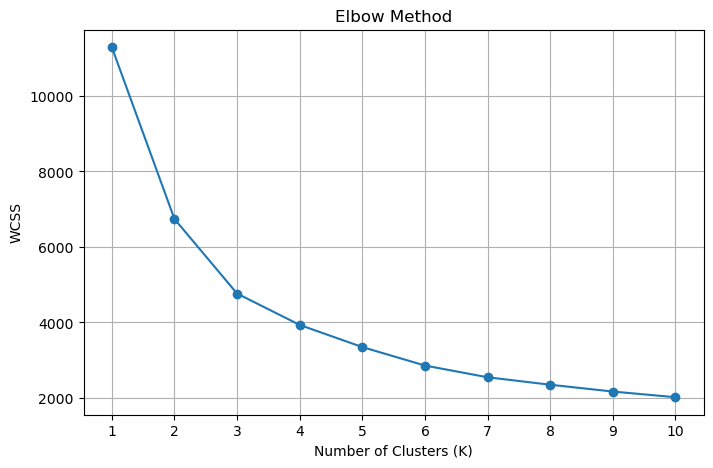


Optimal Number of Clusters: 3

K-Means Cluster Results:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  KMeans_Cluster
0               30      95.70  2871.00    95               2
1               34      81.35  2765.90    95               2
2               41      94.74  3884.34    95               1
3               45      83.26  3746.70    95               1
4               49     100.00  5205.27    95               1

Number of Records in Each K-Means Cluster:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64


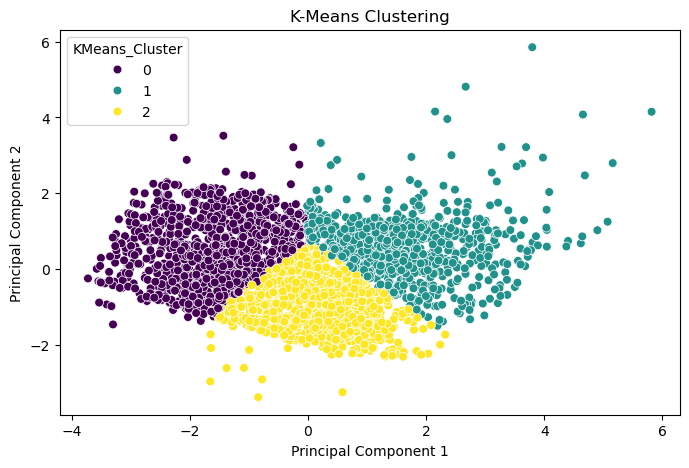


Hierarchical Clustering Results:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  Hierarchical_Cluster
0               30      95.70  2871.00    95                     2
1               34      81.35  2765.90    95                     2
2               41      94.74  3884.34    95                     0
3               45      83.26  3746.70    95                     0
4               49     100.00  5205.27    95                     1

Number of Records in Each Hierarchical Cluster:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


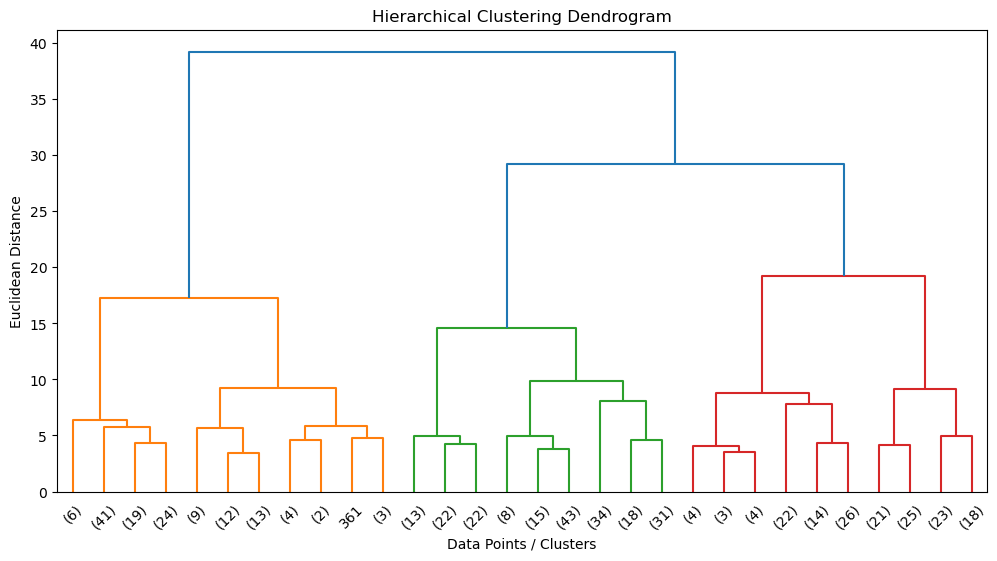

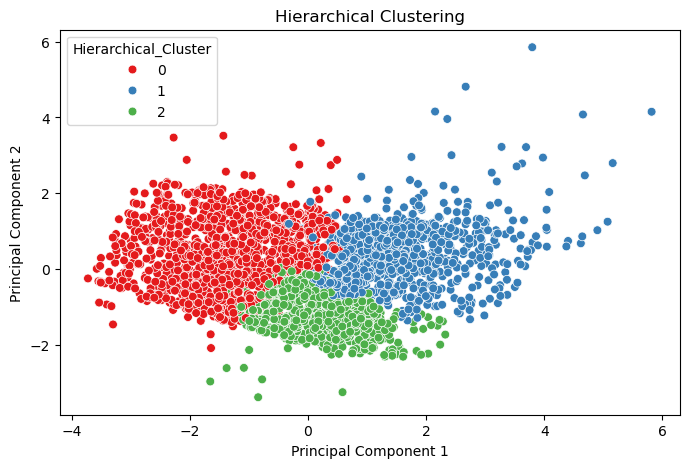


K-Means Cluster Analysis:
                QUANTITYORDERED  PRICEEACH    SALES    MSRP
KMeans_Cluster                                             
0                         35.21      59.55  2101.08   64.15
1                         43.72      97.48  5720.08  127.89
2                         27.60      95.44  3123.06  113.27

Hierarchical Cluster Analysis:
                      QUANTITYORDERED  PRICEEACH    SALES    MSRP
Hierarchical_Cluster                                             
0                               35.48      63.75  2273.01   70.55
1                               41.71      99.29  5575.63  127.05
2                               25.39      97.35  3048.60  117.84

Clustering completed successfully!
Results saved as sales_clustering_results.csv


In [1]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# ==========================================
# 3. DATA PREPROCESSING
# ==========================================

# Select numerical features for clustering
features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

X = df[features].copy()

# Handle missing values
X = X.fillna(X.median())

print("\nSelected Features:")
print(X.head())

# ==========================================
# 4. FEATURE SCALING
# ==========================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ==========================================
# 5. ELBOW METHOD
# ==========================================

wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

# ==========================================
# 6. FIND OPTIMAL NUMBER OF CLUSTERS
# ==========================================

# Estimate elbow using maximum distance
# from the straight line joining endpoints

points = np.array(list(zip(range(1, 11), wcss)))

start = points[0]
end = points[-1]

distances = np.abs(
    np.cross(end - start, points - start)
) / np.linalg.norm(end - start)

optimal_k = np.argmax(distances) + 1

print("\nOptimal Number of Clusters:", optimal_k)

# ==========================================
# 7. K-MEANS CLUSTERING
# ==========================================

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means Cluster Results:")
print(df[features + ["KMeans_Cluster"]].head())

# Cluster distribution
print("\nNumber of Records in Each K-Means Cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

# ==========================================
# 8. VISUALIZE K-MEANS CLUSTERS
# ==========================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["KMeans_Cluster"],
    palette="viridis",
    s=40
)

plt.title("K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# ==========================================
# 9. HIERARCHICAL CLUSTERING
# ==========================================

hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("\nHierarchical Clustering Results:")
print(df[features + ["Hierarchical_Cluster"]].head())

# Cluster distribution
print("\nNumber of Records in Each Hierarchical Cluster:")
print(
    df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

# ==========================================
# 10. DENDROGRAM
# ==========================================

# Use a sample for the dendrogram to reduce computation
sample_size = min(500, len(X_scaled))

np.random.seed(42)

sample_indices = np.random.choice(
    len(X_scaled),
    sample_size,
    replace=False
)

sample_data = X_scaled[sample_indices]

linked = linkage(sample_data, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Euclidean Distance")
plt.show()

# ==========================================
# 11. CLUSTER VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["Hierarchical_Cluster"],
    palette="Set1",
    s=40
)

plt.title("Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# ==========================================
# 12. CLUSTER ANALYSIS
# ==========================================

print("\nK-Means Cluster Analysis:")

print(
    df.groupby("KMeans_Cluster")[features].mean().round(2)
)

print("\nHierarchical Cluster Analysis:")

print(
    df.groupby("Hierarchical_Cluster")[features].mean().round(2)
)

# ==========================================
# 13. SAVE FINAL RESULTS
# ==========================================

df.to_csv("sales_clustering_results.csv", index=False)

print("\nClustering completed successfully!")
print("Results saved as sales_clustering_results.csv")